Sensor types: temperature, humidity, pressure
Sensor selection: temperature
Number of readings: 10
Minimum sensor value: 0.0
Maximum sensor value: 50.0
Alert threshold: 25.0
[13.87959488 21.75855405 43.54045717 48.86805231 45.51519297  7.61937251
 41.7952891  33.52599023 33.90231972 25.16869817]


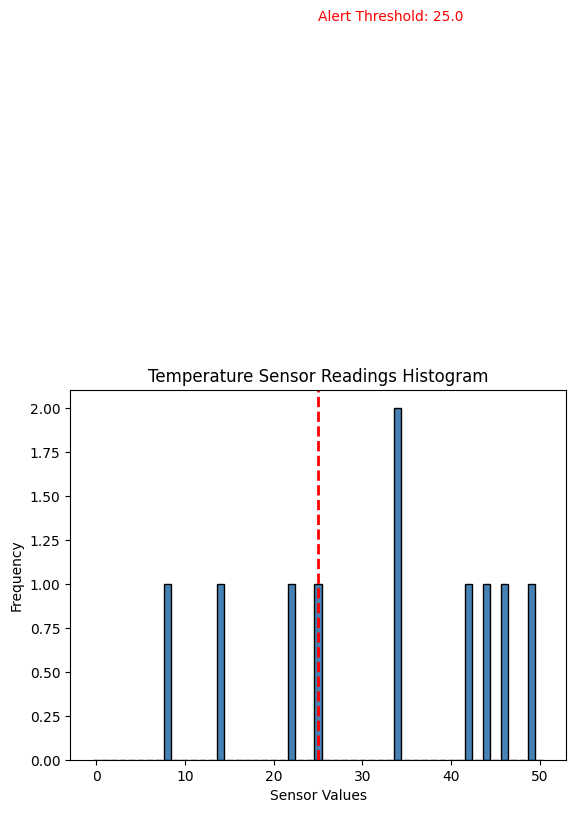

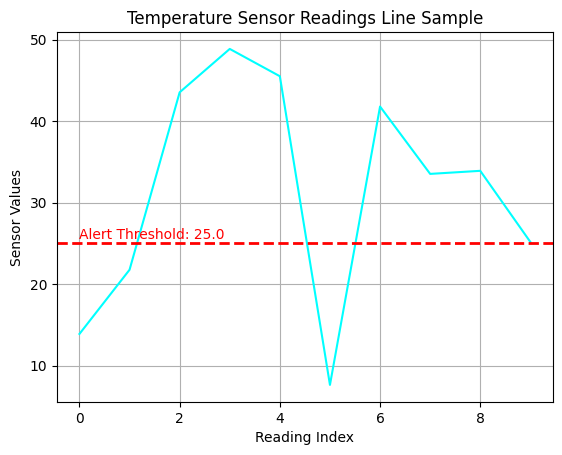

CSV file saved.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt 
import csv as csv


#__1__USER INPUT__ / __8__ERROR HANDLING__ ---------------------------------------------
def get_user_input():
    """ Per functie uitgelegd:
    1 sensor type: De while loop vraagt aan de gebruiker wat voor sensor type hij wilt gebruiken.
    De while loop controleert vervolgens of de input ook in de lijst staat. Anders geeft hij error en vraagt hij opnieuw.

    2 number of readings: Vraagt de hoeveelheid readings die de gebruiker wilt hebben.
    De gebruiker checkt of de input een integer is en of het positief is. Anders komt hier een passende error voor.

    3 minimum: Vraagt de minimale waarde die de sensor als reading kan geven.
    De except checkt of er een float wordt gegeven door de gebruiker. Anders wordt er een error gegeven.

    4 maximum: Vraagt de maximale waarde die de sensor als reading kan geven.
    De except checkt of er een float wordt gegeven door de gebruiker. Anders wordt er een error gegeven. 
    Ook wordt er gechecked of de maximale opgegeven waarde wel hoger is dan de minimale. Anders komt er ook een error.

    5 alert threshold: Vraagt de alert threshold die de sensor als reading kan geven. 
    De except checkt of er een float wordt gegeven door de gebruiker. Anders wordt er een error gegeven. 
    Ook wordt er gechecked of de alert threshold tussen de minimale en maximale waarde ligt. Anders komt er ook een error.                  
    
    Returns:
    Na al deze inputs worden de variabelen teruggegeven in een tuple.
    
    """
    print("Sensor types: temperature, humidity, pressure")
    #sensor type
    while True:
        sensor_selection = input("Select one of the sensor types: ")
        if sensor_selection in ["temperature", "humidity", "pressure"]:
            print("Sensor selection:", sensor_selection)
            break
        print("Please select a valid sensor type.")

    # Number of readings
    while True:
        try:
            num_of_readings = int(input("Select the number of readings: "))
            if num_of_readings > 0:
                print("Number of readings:", num_of_readings)
                break
            print("Please enter a positive number.")
        except ValueError:
            print("Please enter a valid integer.")

    # Minimum
    while True:
        try:
            min_sensor_value = float(input("Select the minimum value for the sensor: "))
            print("Minimum sensor value:", min_sensor_value)
            break
        
        except ValueError:
            print("Please enter a valid number.")

    # Maximum
    while True:
        try:
            max_sensor_value = float(input("Select the maximum value for the sensor: "))
            if max_sensor_value > min_sensor_value:
                print("Maximum sensor value:", max_sensor_value)    
                break
            print("Maximum must be greater than minimum.")
        except ValueError:
            print("Please enter a valid number.")

    # alert threshold
    while True:
        try:
            alert_threshold = float(input("Select the alert threshold for the sensor: "))
            if min_sensor_value <= alert_threshold <= max_sensor_value:
                print("Alert threshold:", alert_threshold)
                break
            print("Threshold must be between minimum and maximum.")
        except ValueError:
            print("Please enter a valid number.")

    return (sensor_selection, num_of_readings, min_sensor_value, max_sensor_value, alert_threshold)


sensor_selection, num_of_readings, min_sensor_value, max_sensor_value, alert_threshold = get_user_input()


#__2__GENERATE SENSOR VALUES__ ---------------------------------------------
def generate_readings(num_of_readings, min_sensor_value, max_sensor_value):
    """Deze functie genereert een lijst met willekeurige getallen. Dit wordt gedaan op basis van 3 invoer parameters. 
    Deze bepalen de hoeveelheid gegenereerde getallen en de min en max waarden. Dit wordt direct gedaan met de np.randomo.uniform functie.
    Uniform betekent dat de kans op een getal tussen de min en max gelijk is. Ook genereerd het komma getallen. 
    Vervolgens komen deze getallen in een lijst genaamd sensor_values."""
    return np.random.uniform(min_sensor_value, max_sensor_value, num_of_readings)
sensor_values = generate_readings(num_of_readings, min_sensor_value, max_sensor_value)
print(sensor_values)




#__3__ANALYSING WITH NUMPY__ -----------------------------------------------

def calculate_statistics(sensor_values):
    """Genereert statistieken van de sensor readings. Dit wordt gedaan met numpy functies. Aantal readings wordt berekend meet len. 
    De min en max reading wordt gedaan met de functie np.min en np.max. Het gemmidelde getal wordt berekend met np.mean en np.std berekend de gemiddelde spreiding.
    Dit wordt allemaal teruggegeven in een tuple."""
    num_readings = len(sensor_values)
    max_value = np.max(sensor_values)
    min_value = np.min(sensor_values)
    mean_value = np.mean(sensor_values)
    standard_deviation = np.std(sensor_values)
    return num_readings, max_value, min_value, mean_value, standard_deviation
calculate_statistics(sensor_values)

def find_outliers(sensor_values, alert_threshold):
    """deze functie telt het aantal readings dat boven de alert threshold ligt. Dit wordt gedaan met np.sum en een boolean check.
    Ook telt het aantal duplicaten in de readings. Dit wordt gedaan door met de np.sum te kijken welke boven de alert threshold liggen. 
    Deze True values worden opgeteld en teruggegeven in een tuple."""
    num_above_alert_threshold = np.sum(sensor_values > alert_threshold)
    return num_above_alert_threshold
find_outliers(sensor_values, alert_threshold)

#__4__VISUALIZATION__ -----------------------------------------------------

def plot_histogram(sensor_values, min_sensor_value, max_sensor_value, alert_threshold): 
    """Deze functie maakt een staafdiagram van de sensor readings. Dit wordt gedaan met matplotlib.pyplot. De histogram wordt gemaakt met plt.hist.
    De bins(staven) worden gemaakt met np.arange. De alert threshold wordt weergegeven met een rode stipppellijn die de funcite axvline plot. 
    Ook wordt er een titel, x en y as label toegevoegd. De alert threshold wordt ook weergegeven met plt.text."""
    plt.hist(sensor_values, bins=np.arange(min_sensor_value - 0.5, max_sensor_value + 1.5, 1), rwidth=0.8, color='steelblue', edgecolor='black')
    plt.axvline(alert_threshold, color='red', linestyle='--', linewidth=2)
    plt.title(f"{sensor_selection.capitalize()} Sensor Readings Histogram")
    plt.xlabel("Sensor Values")
    plt.ylabel("Frequency")
    plt.text(alert_threshold, plt.ylim()[1]*1, f'Alert Threshold: {alert_threshold}', color='red', rotation=0)
    plt.show()
plot_histogram(sensor_values, min_sensor_value, max_sensor_value, alert_threshold)

def plot_grid(sensor_values, num_of_readings):
    """Deze functie maakt een lijngrafiek van de sensor readings. Dit wordt gedaan met matplotlib.pyplot. De lijngrafiek wordt gemaakt met plt.plot. 
    De range wordt bepaalde met de hoeveelheid readings. Verder worden de sensor waarden erin gezet en de stijl van de grafiek gemaakt. Er wordt een titel, x en y as label toegevoegd en 
    de alert threshold wordt weergegeven met een rode stipppellijn die de functie axhline plot."""
    plt.grid()  
    plt.plot(range(num_of_readings), sensor_values, linestyle='-', color='steelblue')
    plt.axhline(alert_threshold, color='red', linestyle='--', linewidth=2)
    plt.title(f"{sensor_selection.capitalize()} Sensor Readings Line Sample")
    plt.xlabel("Reading Index")
    plt.ylabel("Sensor Values")
    plt.text(0, alert_threshold + 0.5, f'Alert Threshold: {alert_threshold}', color='red')
    plt.show()
plot_grid(sensor_values, num_of_readings)


#__5__SAVING DATA__ -----------------------------------------------------


def save_readings(filename, sensor_values):
    """Deze functie slaat de sensor readings op in een CSV bestand. Dit wordt gedaan met de csv module.
    De functie opent een bestand met de naam die de gebruiker heeft opgegeven. Vervolgens wordt er een writer object gemaakt.
    De eerste rij wordt de header van het bestand. Daarna wordt er een for loop gemaakt die door de sensor readings heen loopt.
    De enumerate functie wordt gebruikt om het sample nummer bij te houden."""
    with open(filename, "w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)
        writer.writerow(["Sample Number", "Sensor Value"])

        for sample_number, value in enumerate(sensor_values, start=1):
            writer.writerow([sample_number, value])

save_readings("readings.csv", sensor_values)

print("CSV file saved.")



